# Лабораторная работа №1 по моделированию

**Вариант 22 · Группа P3315 · Линейский Аким Евгеньевич**  

In [1]:
from pathlib import Path
import math
import json
import numpy as np
import matplotlib.pyplot as plt

SIZES = [10, 20, 50, 100, 200, 300]
TP = {'0.9': 1.643, '0.95': 1.960, '0.99': 2.576}
SEED = 22
OUT = Path('results_variant22')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', dpi=180)
    plt.show()
    plt.close(fig)

def fmt(value, digits=3):
    return f'{value:.{digits}f}'.replace('.', ',')

LABELS = [('Мат. ожидание', 'mean'), ('Дов. инт. 0,9', 'ci_0.9'),
          ('Дов. инт. 0,95', 'ci_0.95'), ('Дов. инт. 0,99', 'ci_0.99'),
          ('Дисперсия', 'variance'), ('СКО', 'std'), ('Коэф. вариации', 'cv')]

def print_form(rows, reference):
    print(f"{'Характеристика':<19} {'Строка':<7}" +
          ''.join(f"{row['n']:>12}" for row in rows))
    for label, key in LABELS:
        values = [('± ' if key.startswith('ci_') else '') + fmt(row[key])
                  for row in rows]
        delta = [100 * (row[key] / base[key] - 1)
                 for row, base in zip(rows, reference)]
        print(f"{label:<19} {'Знач.':<7}" + ''.join(f'{v:>12}' for v in values))
        print(f"{'':<19} {'%':<7}" + ''.join(f'{fmt(v, 2):>12}' for v in delta))

In [2]:
INPUT_PATH = None  # Например: "modeling_variant.txt"

DATA_TEXT = """
170,024 79,539 130,762 90,089 163,334 136,418
200,392 293,442 219,744 380,663 195,666 322,105
490,399 364,577 58,487 72,014 177,088 183,206
22,328 98,121 140,249 221,596 86,552 90,440
233,314 16,709 169,271 47,460 275,898 40,941
313,818 60,952 34,950 54,336 329,629 192,693
192,847 194,905 110,372 209,361 180,888 288,685
130,890 584,312 380,720 165,779 236,191 94,679
111,330 248,540 361,398 98,416 63,981 303,634
86,800 208,942 263,589 88,757 43,298 131,125
214,791 208,163 223,119 179,650 40,163 189,742
243,522 112,035 340,319 404,583 294,998 72,711
251,290 20,030 146,130 100,434 150,415 199,821
87,417 257,168 15,892 14,836 51,800 418,550
7,929 62,499 174,340 18,645 159,722 46,789
96,408 116,752 96,128 164,833 68,306 420,383
118,449 42,489 222,866 141,328 115,424 58,955
38,136 126,614 103,409 116,393 74,402 22,548
92,365 82,353 126,877 39,683 179,549 170,339
92,796 292,580 35,073 35,910 365,053 99,318
170,044 439,059 470,488 357,771 430,030 73,933
83,735 52,641 93,914 38,858 80,181 49,148
323,159 195,029 129,108 98,240 441,188 153,093
199,637 79,140 120,930 83,837 89,329 239,461
160,427 262,283 155,024 11,625 241,299 22,612
58,050 39,053 243,639 218,856 76,824 327,907
136,962 371,455 101,572 329,667 115,963 161,151
296,856 119,736 109,337 117,836 176,364 117,964
190,672 62,132 171,453 330,865 405,409 223,720
239,713 199,497 49,795 61,673 52,205 72,039
99,700 233,580 150,956 198,003 201,332 108,135
80,208 173,854 144,678 175,169 129,944 142,436
79,915 86,711 56,352 43,214 140,616 206,702
168,478 137,919 51,298 244,433 207,864 97,953
32,952 255,189 133,041 100,125 140,072 196,401
119,388 175,919 266,864 199,475 101,431 365,202
270,031 177,405 175,620 140,164 289,649 139,261
205,318 132,671 253,934 172,386 119,386 90,815
94,161 301,453 40,729 237,380 52,348 13,091
270,564 637,907 99,353 96,998 214,060 215,158
166,624 128,606 173,574 143,082 478,023 322,467
284,337 46,326 141,568 202,882 18,524 49,681
138,104 334,007 43,652 650,381 116,376 53,596
436,236 158,582 192,722 205,115 70,249 138,277
42,582 264,834 151,359 125,369 266,426 364,757
61,749 10,127 65,263 40,274 55,823 153,138
218,336 220,224 376,028 89,408 97,385 112,528
25,728 109,802 413,923 204,841 142,826 265,614
48,349 348,667 257,964 186,919 132,503 486,858
219,577 123,580 151,368 109,114 288,021 138,902
"""

text = Path(INPUT_PATH).read_text(encoding="utf-8-sig") if INPUT_PATH else DATA_TEXT
x = np.array([float(value.replace(",", ".")) for value in text.split()])
if len(x) != 300 or not np.all(np.isfinite(x)):
    raise ValueError("Нужны ровно 300 конечных чисел.")
print("Количество значений:", len(x))
print("Первые 10 значений:", x[:10])
print("Минимум:", fmt(x.min()), "Максимум:", fmt(x.max()))

Количество значений: 300
Первые 10 значений: [170.024  79.539 130.762  90.089 163.334 136.418 200.392 293.442 219.744
 380.663]
Минимум: 7,929 Максимум: 650,381


## 2 Числовые характеристики исходной последовательности

$$\widetilde m=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad
\widetilde D=\frac{\sum_{i=1}^{n}(X_i-\widetilde m)^2}{n-1}.$$
$$\widetilde\sigma=\sqrt{\widetilde D},\quad \nu=\frac{\widetilde\sigma}{\widetilde m},\quad
\varepsilon_p=t_p\sqrt{\frac{\widetilde D}{n}}.$$

Используется несмещённая дисперсия (`ddof=1`). Коэффициенты из таблицы методички:
1,643; 1,960; 2,576 для вероятностей 0,9; 0,95; 0,99.

In [3]:
def characteristics(x):
    result = []
    for n in SIZES:
        a = x[:n]
        m = float(a.mean())
        d = float(a.var(ddof=1))
        s = math.sqrt(d)
        result.append({'n': n, 'mean': m, 'variance': d, 'std': s,
                       'cv': s/m, **{f'ci_{p}': t*s/math.sqrt(n) for p,t in TP.items()}})
    return result

sx = characteristics(x)
print_form(sx, [sx[-1]] * len(sx))

Характеристика      Строка           10          20          50         100         200         300
Мат. ожидание       Знач.       186,441     192,420     185,734     171,321     163,407     169,573
                    %              9,95       13,47        9,53        1,03       -3,64        0,00
Дов. инт. 0,9       Знач.      ± 48,242    ± 44,900    ± 28,099    ± 19,127    ± 12,956    ± 11,004
                    %            338,39      308,01      155,35       73,81       17,74        0,00
Дов. инт. 0,95      Знач.      ± 57,550    ± 53,563    ± 33,521    ± 22,817    ± 15,456    ± 13,128
                    %            338,39      308,01      155,35       73,81       17,74        0,00
Дов. инт. 0,99      Знач.      ± 75,637    ± 70,396    ± 44,056    ± 29,988    ± 20,313    ± 17,253
                    %            338,39      308,01      155,35       73,81       17,74        0,00
Дисперсия           Знач.      8621,419   14936,197   14624,635   13552,104   12436,542   13457,969


In [4]:
for probability in TP:
    half = sx[-1][f'ci_{probability}']
    print(f'p = {probability}: [{fmt(x.mean() - half)}; {fmt(x.mean() + half)}]')
print(f"Среднее: {fmt(sx[-1]['mean'])}; дисперсия: {fmt(sx[-1]['variance'])}; "
      f"СКО: {fmt(sx[-1]['std'])}; коэффициент вариации: {fmt(sx[-1]['cv'], 6)}")

p = 0.9: [158,569; 180,578]
p = 0.95: [156,446; 182,701]
p = 0.99: [152,320; 186,827]
Среднее: 169,573; дисперсия: 13457,969; СКО: 116,008; коэффициент вариации: 0,684120


## 3 График значений исходной последовательности

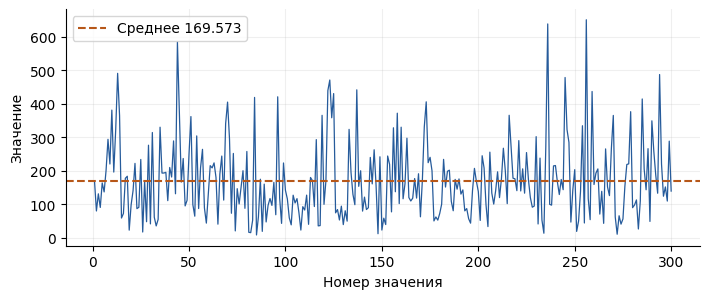

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.plot(range(1, 301), x, lw=0.9, color='#265b9b')
ax.axhline(x.mean(), ls='--', color='#b75718', label=f'Среднее {x.mean():.3f}')
ax.set(xlabel='Номер значения', ylabel='Значение')
ax.grid(alpha=0.2)
ax.legend()
show_figure(fig, 'original')

## 4 Автокорреляционный анализ исходной последовательности

 k |   r(k)  | нижняя граница | верхняя граница
 1 |  0.0835 |        -0.0296 |         0.1967
 2 |  0.0523 |        -0.0617 |         0.1662
 3 |  0.0783 |        -0.0360 |         0.1925
 4 |  0.0101 |        -0.1048 |         0.1251
 5 | -0.0915 |        -0.2065 |         0.0234
 6 | -0.0347 |        -0.1506 |         0.0812
 7 | -0.0109 |        -0.1270 |         0.1051
 8 | -0.1287 |        -0.2447 |        -0.0127
 9 |  0.1525 |         0.0346 |         0.2703
10 |  0.0494 |        -0.0709 |         0.1698


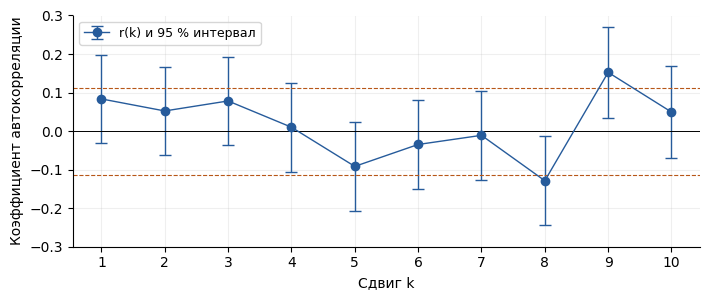

Интервал не содержит ноль на сдвигах: [8, 9]


In [6]:
def autocorrelation(x, max_lag=10):
    z = x - x.mean()
    r = np.array([np.dot(z[:-k],z[k:])/np.dot(z,z) for k in range(1,max_lag+1)])
    w = 1.96*np.sqrt((1+2*np.r_[0,np.cumsum(r*r)[:-1]])/len(x))
    return r,w

def plot_acf(seq, name):
    r, w = autocorrelation(seq)
    fig, ax = plt.subplots(figsize=(7.2, 3.1))
    ax.errorbar(range(1, 11), r, yerr=w, fmt='o-', capsize=4,
                lw=1, color='#265b9b', label='r(k) и 95 % интервал')
    ax.axhline(0, color='black', lw=0.7)
    bound = 1.96 / math.sqrt(len(seq))
    for value in [-bound, bound]:
        ax.axhline(value, color='#b75718', ls='--', lw=0.8)
    ax.set(xlabel='Сдвиг k', ylabel='Коэффициент автокорреляции',
           xticks=range(1, 11), ylim=(-0.30, 0.30))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
    show_figure(fig, name)

rx, wx = autocorrelation(x)
print(' k |   r(k)  | нижняя граница | верхняя граница')
for k, (r, w) in enumerate(zip(rx, wx), 1):
    print(f'{k:2d} | {r:7.4f} | {r-w:14.4f} | {r+w:14.4f}')
plot_acf(x, 'original_acf')
print('Интервал не содержит ноль на сдвигах:', (np.flatnonzero(abs(rx) > wx) + 1).tolist())

## 5 Гистограмма исходной последовательности

Ширина интервала: 71,383556
 № |       Левая граница |      Правая граница | Число | Частота
 1 |            7.929000 |           79.312556 |    66 | 0.2200
 2 |           79.312556 |          150.696111 |    90 | 0.3000
 3 |          150.696111 |          222.079667 |    69 | 0.2300
 4 |          222.079667 |          293.463222 |    34 | 0.1133
 5 |          293.463222 |          364.846778 |    19 | 0.0633
 6 |          364.846778 |          436.230333 |    12 | 0.0400
 7 |          436.230333 |          507.613889 |     7 | 0.0233
 8 |          507.613889 |          578.997444 |     0 | 0.0000
 9 |          578.997444 |          650.381000 |     3 | 0.0100


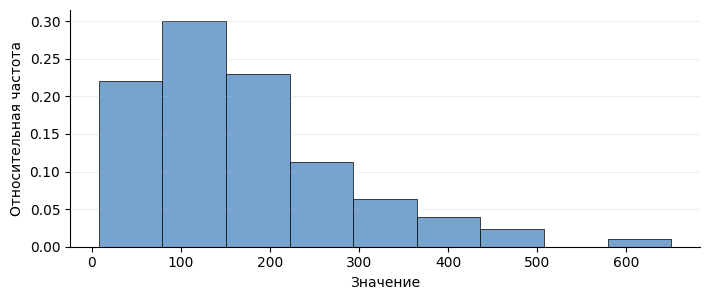

In [7]:
counts, edges = np.histogram(x, bins=9)
h = edges[1] - edges[0]
print('Ширина интервала:', fmt(h, 6))
print(' № |       Левая граница |      Правая граница | Число | Частота')
for j, count in enumerate(counts):
    print(f'{j+1:2d} | {edges[j]:19.6f} | {edges[j+1]:19.6f} | '
          f'{count:5d} | {count/300:.4f}')
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.hist(x, bins=edges, weights=np.full(300, 1/300),
        color='#77a3cf', edgecolor='black', lw=0.5)
ax.set(xlabel='Значение', ylabel='Относительная частота')
ax.grid(axis='y', alpha=0.2)
show_figure(fig, 'original_hist')

## 6 Аппроксимирующий закон распределения

In [8]:
def parameters(x):
    t = float(x.mean())
    d = float(x.var(ddof=1))
    nu = math.sqrt(d)/t
    if not 1/math.sqrt(3) < nu < 1/math.sqrt(2):
        raise ValueError('Этот генератор предназначен для трёхфазной модели варианта 22.')
    k = math.ceil(1/nu**2)
    k1,k2 = 1,k-1
    t1 = t/k*(1+math.sqrt(k2/k1*(k*nu**2-1)))
    t2 = (t-k1*t1)/k2
    return {'t': t, 'd': d, 'nu': nu, 'k': k, 'k1': k1, 'k2': k2,
            't1': t1, 't2': t2, 'lambda1': 1/t1, 'lambda2': 1/t2}

p = parameters(x)
for name, value in p.items():
    print(f'{name:>8} = {value:.9f}')
print('Проверка среднего:', p['t1'] + 2*p['t2'])
print('Проверка дисперсии:', p['t1']**2 + 2*p['t2']**2)

       t = 169.573210000
       d = 13457.968585544
      nu = 0.684120357
       k = 3.000000000
      k1 = 1.000000000
      k2 = 2.000000000
      t1 = 107.337420491
      t2 = 31.117894755
 lambda1 = 0.009316415
 lambda2 = 0.032135850
Проверка среднего: 169.57321000000002
Проверка дисперсии: 13457.968585544382


## 7 Генератор случайных величин

In [9]:
def generate(p, seed):
    rng = np.random.default_rng(seed)
    u = rng.random((300,3))
    u = np.maximum(u,np.finfo(float).tiny)
    return -(p['t1']*np.log(u[:,0])+p['t2']*np.log(u[:,1])+p['t2']*np.log(u[:,2]))

y = generate(p, SEED)
sy = characteristics(y)
print('Сгенерировано значений:', len(y))
print('Первые 10:', y[:10])
print('Среднее:', fmt(y.mean(), 6), 'Дисперсия:', fmt(y.var(ddof=1), 6))

Сгенерировано значений: 300
Первые 10: [233.41033139  70.30807154 115.12290738 171.77630493 161.53951804
 121.95745731 139.09299465 284.83156934  76.02946568  94.0695826 ]
Среднее: 176,015361 Дисперсия: 13987,182434


## 8 Числовые характеристики сгенерированной последовательности

In [10]:
print_form(sy, sx)
print('Отклонения полной выборки:')
for label, key in LABELS:
    delta = 100 * (sy[-1][key]/sx[-1][key] - 1)
    print(f'{label}: {fmt(delta, 2)} %')
print('Разность средних:', fmt(abs(y.mean()-x.mean())))
print('Исходный полуинтервал p=0,95:', fmt(sx[-1]['ci_0.95']))

Характеристика      Строка           10          20          50         100         200         300
Мат. ожидание       Знач.       146,814     125,053     137,799     163,442     175,649     176,015
                    %            -21,25      -35,01      -25,81       -4,60        7,49        3,80
Дов. инт. 0,9       Знач.      ± 35,794    ± 27,194    ± 16,260    ± 15,452    ± 13,500    ± 11,219
                    %            -25,80      -39,43      -42,13      -19,21        4,20        1,95
Дов. инт. 0,95      Знач.      ± 42,700    ± 32,441    ± 19,398    ± 18,434    ± 16,105    ± 13,383
                    %            -25,80      -39,43      -42,13      -19,21        4,20        1,95
Дов. инт. 0,99      Знач.      ± 56,120    ± 42,637    ± 25,494    ± 24,227    ± 21,167    ± 17,589
                    %            -25,80      -39,43      -42,13      -19,21        4,20        1,95
Дисперсия           Знач.      4746,122    5479,169    4897,240    8845,276   13503,455   13987,182


## 9 График и гистограмма сгенерированной последовательности

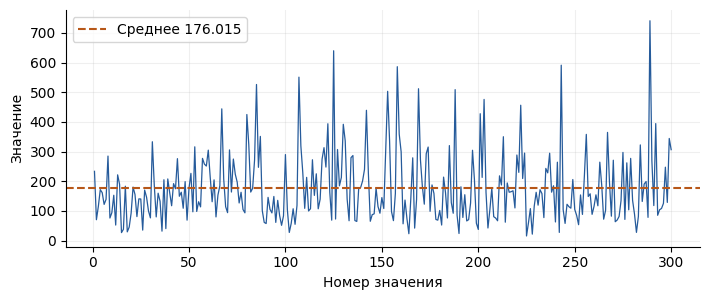

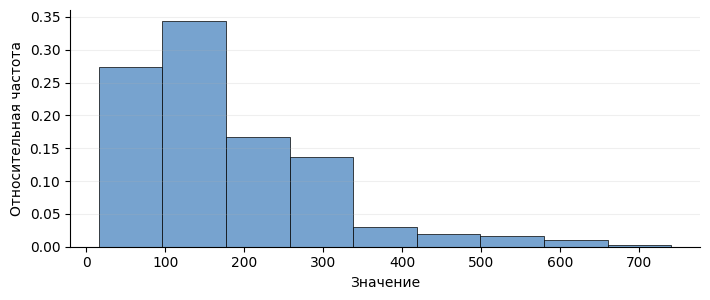

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.plot(range(1, 301), y, lw=0.9, color='#265b9b')
ax.axhline(y.mean(), ls='--', color='#b75718', label=f'Среднее {y.mean():.3f}')
ax.set(xlabel='Номер значения', ylabel='Значение')
ax.grid(alpha=0.2)
ax.legend()
show_figure(fig, 'generated')

fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.hist(y, bins=np.linspace(y.min(), y.max(), 10), weights=np.full(300, 1/300),
        color='#77a3cf', edgecolor='black', lw=0.5)
ax.set(xlabel='Значение', ylabel='Относительная частота')
ax.grid(axis='y', alpha=0.2)
show_figure(fig, 'generated_hist')

## 10 Сравнение исходной гистограммы с теоретической плотностью

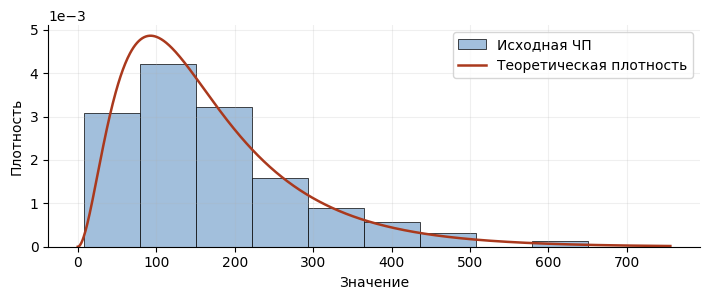

Первые три фактические частоты: [0.22 0.3  0.23]
Первые три теоретические вероятности: [0.21027041 0.32525323 0.21637675]


In [12]:
def density(x,p):
    a,b = p['lambda1'],p['lambda2']
    delta = b-a
    x = np.maximum(np.asarray(x),0)
    return a*b*b/delta**2*np.exp(-a*x)*(-np.expm1(-delta*x)-delta*x*np.exp(-delta*x))

def cdf(x,p):
    a,b = p['lambda1'],p['lambda2']
    delta = b-a
    x = np.maximum(np.asarray(x),0)
    return a*b*b/delta**2*((1-np.exp(-a*x))/a-(1-np.exp(-b*x))/b
                         -delta*(1-np.exp(-b*x)*(1+b*x))/b**2)

grid = np.linspace(0, max(x.max(), y.max())*1.02, 1000)
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.hist(x, bins=edges, density=True, color='#a2bfdc',
        edgecolor='black', lw=0.5, label='Исходная ЧП')
ax.plot(grid, density(grid, p), color='#aa391d', lw=1.8,
        label='Теоретическая плотность')
ax.set(xlabel='Значение', ylabel='Плотность')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.grid(alpha=0.2)
ax.legend()
show_figure(fig, 'density')
print('Первые три фактические частоты:', counts[:3]/300)
print('Первые три теоретические вероятности:', np.diff(cdf(edges, p))[:3])

## 11 Сравнение двух последовательностей

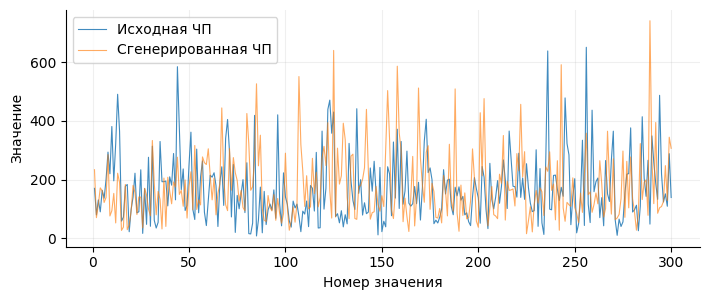

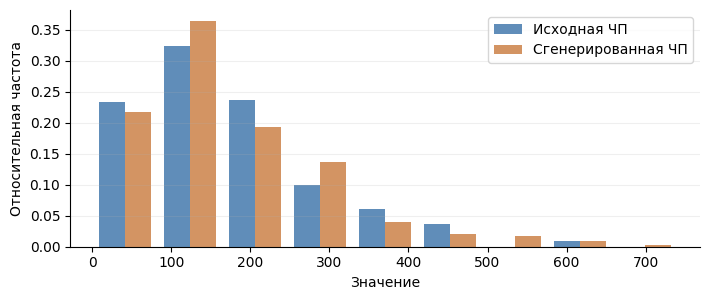

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.plot(range(1, 301), x, lw=0.8, alpha=0.85, label='Исходная ЧП')
ax.plot(range(1, 301), y, lw=0.8, alpha=0.65, label='Сгенерированная ЧП')
ax.set(xlabel='Номер значения', ylabel='Значение')
ax.grid(alpha=0.2)
ax.legend()
show_figure(fig, 'comparison_values')

common = np.linspace(0, max(x.max(), y.max()), 10)
cx, _ = np.histogram(x, bins=common)
cy, _ = np.histogram(y, bins=common)
center = (common[:-1] + common[1:])/2
width = common[1] - common[0]
fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.bar(center-width*0.2, cx/300, width*0.4, color='#608db9', label='Исходная ЧП')
ax.bar(center+width*0.2, cy/300, width*0.4, color='#d39463', label='Сгенерированная ЧП')
ax.set(xlabel='Значение', ylabel='Относительная частота')
ax.grid(axis='y', alpha=0.2)
ax.legend()
show_figure(fig, 'comparison_hist')

## 12 Автокорреляция сгенерированной последовательности и форма 3

 k |  r исход. |    r ген. | Отклонение, %
 1 |    0.0835 |    0.0925 |          10.7
 2 |    0.0523 |    0.0086 |         -83.6
 3 |    0.0783 |    0.0042 |         -94.6
 4 |    0.0101 |   -0.0395 |        -490.7
 5 |   -0.0915 |    0.0310 |         133.9
 6 |   -0.0347 |    0.0094 |         127.2
 7 |   -0.0109 |   -0.0047 |          56.9
 8 |   -0.1287 |   -0.0342 |          73.4
 9 |    0.1525 |   -0.0496 |        -132.5
10 |    0.0494 |    0.0239 |         -51.7


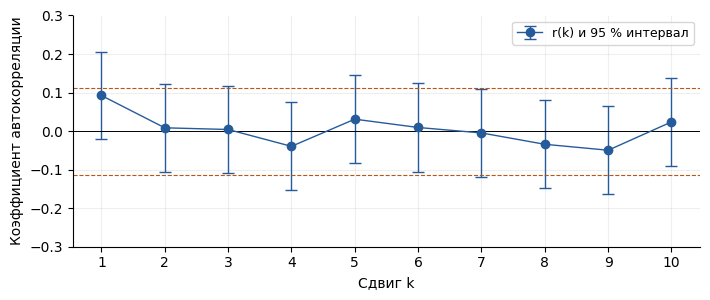

Интервал не содержит ноль на сдвигах: []


In [14]:
ry, wy = autocorrelation(y)
acf_delta = 100*(ry-rx)/np.abs(rx)
print(' k |  r исход. |    r ген. | Отклонение, %')
for k, (a, b, delta) in enumerate(zip(rx, ry, acf_delta), 1):
    print(f'{k:2d} | {a:9.4f} | {b:9.4f} | {delta:13.1f}')
plot_acf(y, 'generated_acf')
print('Интервал не содержит ноль на сдвигах:', (np.flatnonzero(abs(ry) > wy) + 1).tolist())

## 13 Взаимная корреляция

In [15]:
pearson = float(np.corrcoef(x, y)[0, 1])
print('Коэффициент корреляции Пирсона:', fmt(pearson, 6))

Коэффициент корреляции Пирсона: 0,129778


## 14 Итоговые результаты и сохранение файлов

In [16]:
result = {
    'seed': SEED, 'parameters': p, 'original': sx, 'generated': sy,
    'original_deviations': [{key: 100*(row[key]/sx[-1][key]-1)
                              for key in row if key != 'n'} for row in sx],
    'generated_deviations': [{key: 100*(b[key]/a[key]-1)
                               for key in a if key != 'n'} for a, b in zip(sx, sy)],
    'acf_original': rx.tolist(), 'acf_generated': ry.tolist(),
    'acf_width_original': wx.tolist(), 'acf_width_generated': wy.tolist(),
    'acf_deviations': acf_delta.tolist(), 'pearson': pearson,
    'hist_edges': edges.tolist(), 'hist_counts': counts.tolist(),
    'hist_theoretical': np.diff(cdf(edges, p)).tolist(),
}
(OUT/'results.json').write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding='utf-8')
np.savetxt(OUT/'generated_sequence.txt', y, fmt='%.12f')
print('Среднее исходной ЧП:', fmt(x.mean(), 6))
print('Среднее сгенерированной ЧП:', fmt(y.mean(), 6))
print('Отклонение среднего:', fmt(100*(y.mean()/x.mean()-1), 2), '%')
print('Отклонение дисперсии:', fmt(100*(y.var(ddof=1)/x.var(ddof=1)-1), 2), '%')
print('Параметры закона: одна фаза t1 =', fmt(p['t1'], 6),
      'и две фазы t2 =', fmt(p['t2'], 6))
print('Результаты сохранены в:', OUT)

Среднее исходной ЧП: 169,573210
Среднее сгенерированной ЧП: 176,015361
Отклонение среднего: 3,80 %
Отклонение дисперсии: 3,93 %
Параметры закона: одна фаза t1 = 107,337420 и две фазы t2 = 31,117895
Результаты сохранены в: results_variant22
